In [1]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_squared_error, accuracy_score, f1_score
import os
import pickle
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


os.chdir('../')
print("Current working directory:", os.getcwd())

Current working directory: c:\thesis


In [2]:
# 1. Load the Data
df = pd.read_csv('telemetry_data.csv')
display(df.head())

,timestamp,sfc_type,network_active_nodes,network_free_cpu,network_free_bw,net_max_node_utilization,net_bottleneck_bw,action_max_path_distance,action_num_unique_nodes,outcome_accepted,outcome_latency
0,9.48,VoIP,0,1200.0,15000.0,0.0,1000.0,3,4,1,52
1,12.79,VoIP,4,1145.0,14880.0,20.0,980.0,4,4,1,88
2,35.64,Video,4,1145.0,14880.0,20.0,980.0,1,3,1,13
3,41.23,Web,6,1085.0,14780.0,30.0,950.0,5,3,1,79
4,47.94,Web,7,1060.0,14690.0,40.0,950.0,6,3,1,80


In [3]:
# 2. Encode categorical state feature
encoder = LabelEncoder()
df['sfc_type_encoded'] = encoder.fit_transform(df['sfc_type'])

# Save the encoder mapping for the Simulator to use later
os.makedirs('models', exist_ok=True)
with open('models/label_encoder.pkl', 'wb') as f:
    pickle.dump(encoder, f)

print("Saved -> models/label_encoder.pkl")

Saved -> models/label_encoder.pkl


In [4]:
# 3. Define Features
state_features = [
    'sfc_type_encoded', 'network_active_nodes', 'network_free_cpu', 'network_free_bw', 
    'net_max_node_utilization', 'net_bottleneck_bw'
]
action_features = ['action_max_path_distance', 'action_num_unique_nodes']

# Split features and target for Classifier (Model A) - Use only state features
X_cls = df[state_features]
y_cls = df['outcome_accepted']

# Filter Data for Regressor (Model B) - Only accepted requests! Use both state and action features
df_accepted = df[df['outcome_accepted'] == 1].copy()
X_reg = df_accepted[state_features + action_features]
y_reg = df_accepted['outcome_latency']

print(f"Total samples for Classifier: {len(X_cls)}")
print(f"Accepted samples for Regressor: {len(X_reg)}")

Total samples for Classifier: 21043
Accepted samples for Regressor: 9430


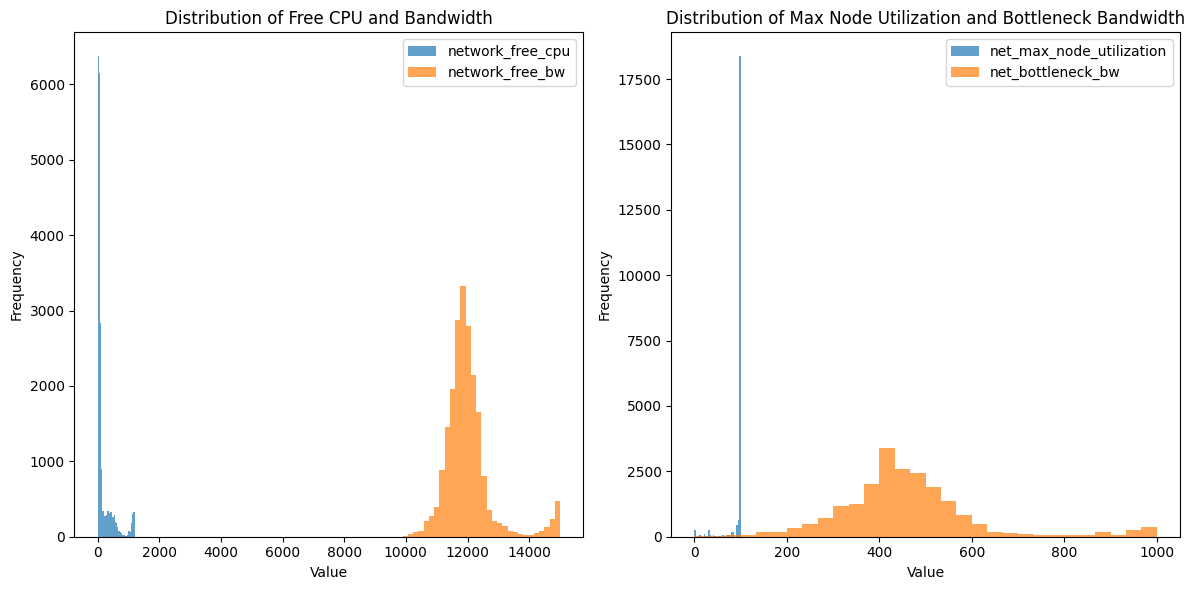

In [5]:
# 4. Plot feature distributions
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.hist(df['network_free_cpu'], bins=30, alpha=0.7, label='network_free_cpu')
plt.hist(df['network_free_bw'], bins=30, alpha=0.7, label='network_free_bw')
plt.title('Distribution of Free CPU and Bandwidth') 
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.legend()
plt.subplot(1, 2, 2)
plt.hist(df['net_max_node_utilization'], bins=30, alpha=0.7, label='net_max_node_utilization')
plt.hist(df['net_bottleneck_bw'], bins=30, alpha=0.7, label='net_bottleneck_bw')
plt.title('Distribution of Max Node Utilization and Bottleneck Bandwidth')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()

In [6]:
# 5. Train Model A: Admission Control (XGBClassifier)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_cls, y_cls, test_size=0.2, random_state=42)

classifier = xgb.XGBClassifier(
    objective='binary:logistic', 
    n_estimators=150, 
    max_depth=5, 
    learning_rate=0.1
)
classifier.fit(X_train_c, y_train_c)

# Evaluate
preds_c = classifier.predict(X_test_c)
print(f"Classifier Accuracy: {accuracy_score(y_test_c, preds_c):.4f}")
print(f"Classifier F1-Score: {f1_score(y_test_c, preds_c):.4f}")

Classifier Accuracy: 0.9499
Classifier F1-Score: 0.9431


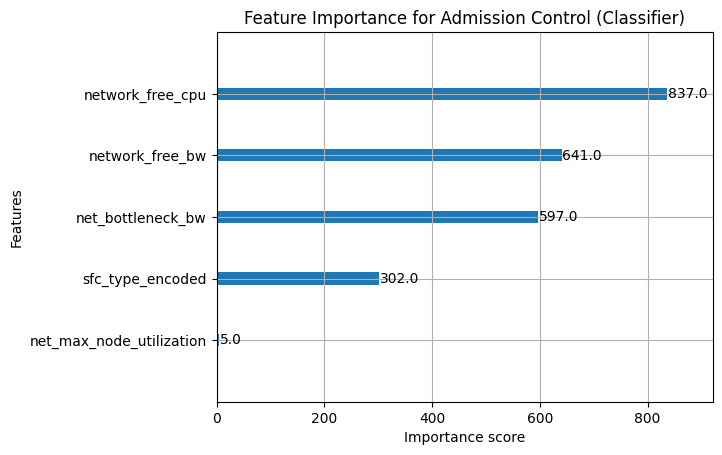

In [7]:
# 6. Plot feature importance for Classifier
xgb.plot_importance(classifier, max_num_features=10)
plt.title('Feature Importance for Admission Control (Classifier)')
plt.show()

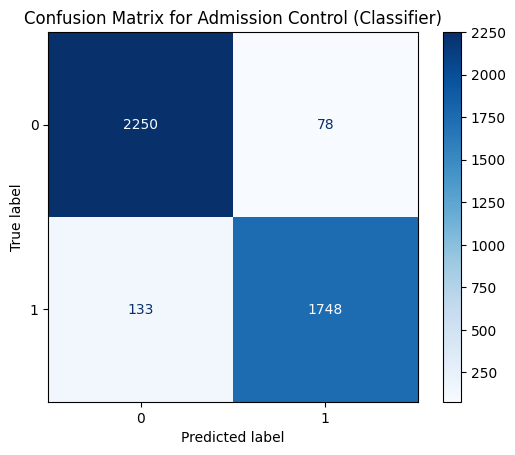

In [8]:
# 7. Plot confusion matrix for Classifier
cm = confusion_matrix(y_test_c, preds_c)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classifier.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix for Admission Control (Classifier)')
plt.show()

In [9]:
# 8. Train Model B: Latency Optimizer (XGBRegressor)
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

regressor = xgb.XGBRegressor(
    objective='reg:squarederror', 
    n_estimators=150, 
    max_depth=5, 
    learning_rate=0.1
)
regressor.fit(X_train_r, y_train_r)

# Evaluate
preds_r = regressor.predict(X_test_r)
rmse = np.sqrt(mean_squared_error(y_test_r, preds_r))
print(f"Regressor Test RMSE: {rmse:.2f}")

Regressor Test RMSE: 11.24


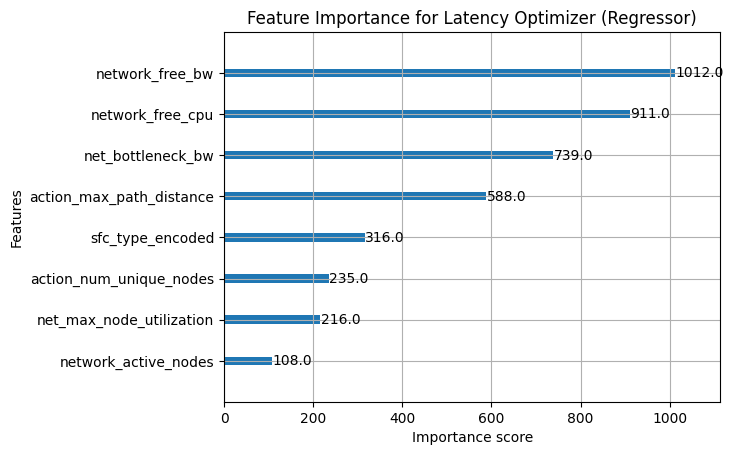

In [10]:
# 9. Plot feature importance for Regressor
xgb.plot_importance(regressor, max_num_features=10)
plt.title('Feature Importance for Latency Optimizer (Regressor)')
plt.show()

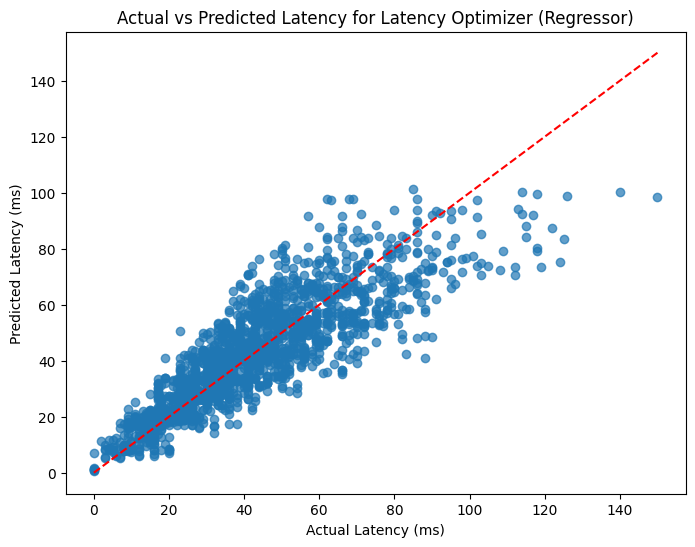

In [11]:
# 10. Plot actual vs predicted latency for Regressor
plt.figure(figsize=(8, 6))
plt.scatter(y_test_r, preds_r, alpha=0.7)
plt.plot([y_test_r.min(), y_test_r.max()], [y_test_r.min(), y_test_r.max()], 'r--')  # Line for perfect predictions
plt.title('Actual vs Predicted Latency for Latency Optimizer (Regressor)')
plt.xlabel('Actual Latency (ms)')
plt.ylabel('Predicted Latency (ms)')
plt.show()

In [12]:
# 7. Save the Ensemble
classifier.save_model('models/kdn_classifier.json')
print("Saved Gatekeeper -> models/kdn_classifier.json")

regressor.save_model('models/kdn_regressor.json')
print("Saved Optimizer -> models/kdn_regressor.json")

Saved Gatekeeper -> models/kdn_classifier.json
Saved Optimizer -> models/kdn_regressor.json
